In [8]:
# =============================================================
# FASE 3 - EDA | Consumo energético en planta siderúrgica
# Celda 1: Librerías, rutas y estilo visual común
# =============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

SEED = 42
np.random.seed(SEED)

BASE_DIR = Path("..")
DATA_PATH = BASE_DIR / "data" / "processed" / "steel_limpio.csv"
FIG_DIR = BASE_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)   # crea la carpeta si no existe

# --- Paleta fija: el mismo color significa lo mismo en TODOS los gráficos ---
# Azul para días laborales y naranja para fin de semana. Es una combinación
# distinguible para personas con daltonismo (no usamos rojo con verde).
COLOR_LABORAL = "#2a78d6"
COLOR_FINDE   = "#eb6834"
COLOR_TEXTO   = "#52514e"
COLOR_INDUCTIVA  = "#6250d6"   # violeta: reactiva de los equipos
COLOR_CAPACITIVA = "#1baf7a"   # verde agua: reactiva de los condensadores

# Estilo sobrio: cuadrícula suave para que destaquen los datos, no el fondo
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": COLOR_TEXTO, "xtick.color": COLOR_TEXTO, "ytick.color": COLOR_TEXTO,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})

In [2]:
# =============================================================
# Celda 2: Carga del dataset limpio (capa plata)
# =============================================================
# Como vimos en el ETL, el CSV no guarda tipos: hay que indicar otra vez
# cuáles columnas son fechas y restaurar el ORDEN de las categorías.
df = pd.read_csv(DATA_PATH, parse_dates=["fecha_hora", "fecha"])

df["tipo_carga"] = pd.Categorical(df["tipo_carga"],
    categories=["Light_Load", "Medium_Load", "Maximum_Load"], ordered=True)
df["dia_semana"] = pd.Categorical(df["dia_semana"],
    categories=["Monday", "Tuesday", "Wednesday", "Thursday",
                "Friday", "Saturday", "Sunday"], ordered=True)
df["turno"] = pd.Categorical(df["turno"],
    categories=["Mañana", "Tarde", "Noche"], ordered=True)
df["tipo_dia"] = df["tipo_dia"].astype("category")

print("Dimensiones:", df.shape)

Dimensiones: (35040, 26)


In [3]:
# =============================================================
# Celda 3: Estadística descriptiva - variables numéricas
# =============================================================
vars_clave = ["consumo_kwh", "demanda_kw", "reactiva_inductiva_kvarh",
              "reactiva_capacitiva_kvarh", "fp_atraso_pct", "fp_adelanto_pct",
              "ratio_reactiva_activa", "co2_estimado_kg", "costo_total_usd"]

desc = df[vars_clave].describe().T
# Dos medidas extra que describe() no trae:
# - Asimetría (skew): 0 = simétrica; > 0 = cola larga hacia valores altos.
# - Coeficiente de variación (CV) = desviación / media: dispersión relativa en %.
desc["asimetria"] = df[vars_clave].skew()
desc["cv_%"] = desc["std"] / desc["mean"] * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,cv_%
consumo_kwh,35040.0,27.39,33.44,2.45,3.20,4.57,51.24,157.18,1.20,122.12
demanda_kw,35040.0,109.55,133.78,9.80,12.80,18.28,204.95,628.72,1.20,122.12
reactiva_inductiva_kvarh,35040.0,13.04,16.31,0.00,2.30,5.00,22.64,96.91,1.44,125.09
reactiva_capacitiva_kvarh,35040.0,3.87,7.42,0.00,0.00,0.00,2.09,27.76,1.73,191.80
fp_atraso_pct,35040.0,80.58,18.92,36.94,63.32,87.96,99.02,100.00,-0.60,23.48
fp_adelanto_pct,35040.0,84.37,30.45,12.50,99.70,100.00,100.00,100.00,-1.51,36.09
ratio_reactiva_activa,35040.0,0.72,0.63,0.00,0.14,0.54,1.22,2.52,0.58,87.89
co2_estimado_kg,35040.0,11.52,14.07,1.03,1.35,1.92,21.56,66.14,1.20,122.12
costo_total_usd,35040.0,2.97,3.41,0.25,0.54,0.72,5.34,16.12,1.18,114.70


In [4]:
# =============================================================
# Celda 4: Variables categóricas + resumen anual de KPIs
# =============================================================
# Frecuencia de cada categoría (en % del total de intervalos)
for col in ["tipo_carga", "tipo_dia", "turno"]:
    print(f"\n{col}:")
    print((df[col].value_counts(normalize=True, sort=False) * 100).round(1))

# ¿Qué turno concentra el consumo? (% de la energía anual)
print("\n% de la energía anual por turno:")
print((df.groupby("turno", observed=True)["consumo_kwh"].sum()
       / df["consumo_kwh"].sum() * 100).round(1))

# Tarjeta de KPIs anuales: el "estado actual" que verá el director de planta
kpis_anuales = pd.Series({
    "Energía total (MWh)": df["consumo_kwh"].sum() / 1000,
    "Demanda máxima (kW)": df["demanda_kw"].max(),
    "Costo total estimado (USD)": df["costo_total_usd"].sum(),
    "Costo por penalización (USD)": df["costo_penalizacion_usd"].sum(),
    "% intervalos penalizados": df["penalizado"].mean() * 100,
    "Emisiones CO2 (t)": df["co2_estimado_kg"].sum() / 1000,
}).round(1)
kpis_anuales


tipo_carga:
tipo_carga
Light_Load      51.6
Medium_Load     27.7
Maximum_Load    20.8
Name: proportion, dtype: float64

tipo_dia:
tipo_dia
Weekday    71.5
Weekend    28.5
Name: proportion, dtype: float64

turno:
turno
Mañana    33.3
Tarde     33.3
Noche     33.3
Name: proportion, dtype: float64

% de la energía anual por turno:
turno
Mañana    43.9
Tarde     49.0
Noche      7.1
Name: consumo_kwh, dtype: float64


Energía total (MWh)                959.6
Demanda máxima (kW)                628.7
Costo total estimado (USD)      104056.4
Costo por penalización (USD)      8092.3
% intervalos penalizados            53.3
Emisiones CO2 (t)                  403.8
dtype: float64

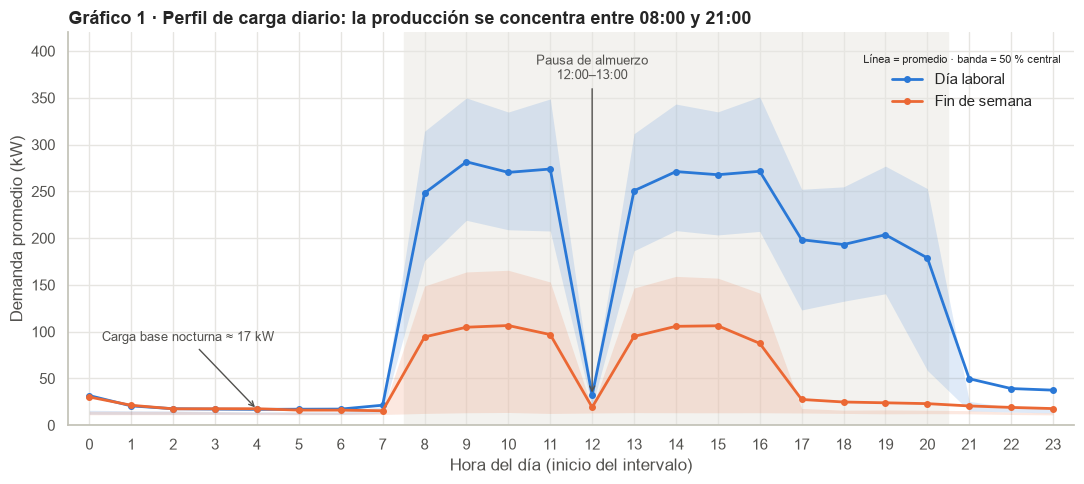

In [5]:
# =============================================================
# Celda 5: GRÁFICO 1 - Perfil de carga diario (laboral vs. fin de semana)
# =============================================================
# Pregunta: ¿a qué horas consume energía la planta y cambia el patrón
# entre días laborales y fines de semana?

# 1) Demanda por hora y tipo de día: promedio y el 50 % central (P25-P75).
#    La banda muestra la variabilidad: un promedio solo esconde
#    si todos los días se parecen o no.
perfil = (df.groupby(["tipo_dia", "hora"], observed=True)["demanda_kw"]
            .agg(promedio="mean",
                 p25=lambda s: s.quantile(0.25),
                 p75=lambda s: s.quantile(0.75))
            .reset_index())

fig, ax = plt.subplots(figsize=(11, 5))

# 2) Una línea con su banda por cada tipo de día
for tipo, color, etiqueta in [("Weekday", COLOR_LABORAL, "Día laboral"),
                              ("Weekend", COLOR_FINDE, "Fin de semana")]:
    d = perfil[perfil["tipo_dia"] == tipo]
    ax.fill_between(d["hora"], d["p25"], d["p75"], color=color, alpha=0.15, linewidth=0)
    ax.plot(d["hora"], d["promedio"], color=color, linewidth=2,
            marker="o", markersize=4, label=etiqueta)

# 3) Contexto: franja de horario productivo y anotaciones de los hallazgos
ax.axvspan(7.5, 20.5, color="#f3f2ef", zorder=0)
ax.annotate("Pausa de almuerzo\n12:00–13:00", xy=(12, 32), xytext=(12, 370),
            ha="center", fontsize=9, color=COLOR_TEXTO,
            arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))
ax.annotate("Carga base nocturna ≈ 17 kW", xy=(4, 17), xytext=(0.3, 90),
            fontsize=9, color=COLOR_TEXTO,
            arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))

# 4) Ejes, título y leyenda. El título ENUNCIA el hallazgo, no solo el tema.
ax.set_xticks(range(24))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, 420)
ax.set_xlabel("Hora del día (inicio del intervalo)")
ax.set_ylabel("Demanda promedio (kW)")
ax.set_title("Gráfico 1 · Perfil de carga diario: la producción se concentra entre 08:00 y 21:00")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.98),
          title="Línea = promedio · banda = 50 % central", title_fontsize=8)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "g1_perfil_carga.png", dpi=150, bbox_inches="tight")  # para el reporte PDF
plt.show()

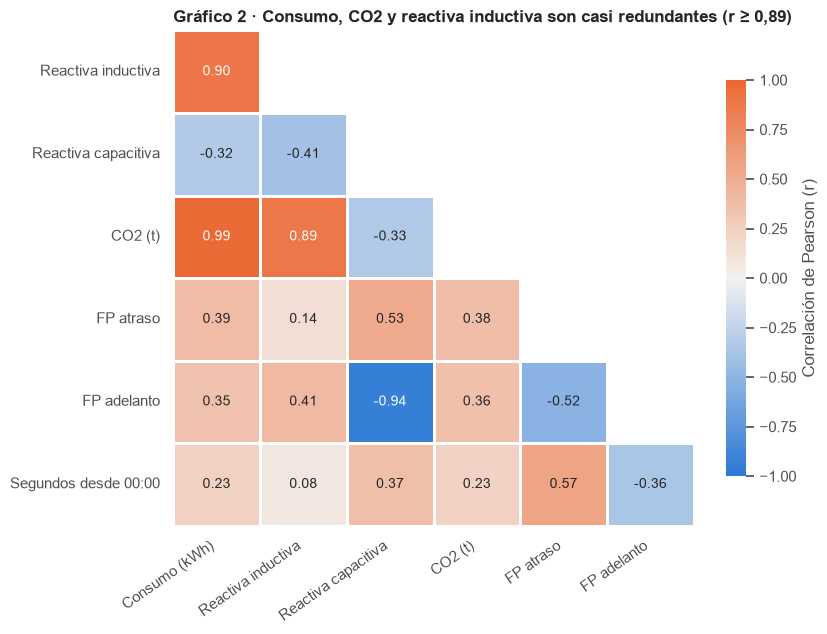

In [6]:
# =============================================================
# Celda 6: GRÁFICO 2 - Matriz de correlación de variables energéticas
# =============================================================
# Usamos solo las 7 variables numéricas ORIGINALES.
# ¿Por qué no las derivadas? Porque muchas son cálculos de otras
# (demanda_kw = consumo_kwh × 4 → correlación de 1 exacto). Incluirlas
# llenaría la matriz de relaciones obvias que no enseñan nada.
etiquetas = {
    "consumo_kwh": "Consumo (kWh)",
    "reactiva_inductiva_kvarh": "Reactiva inductiva",
    "reactiva_capacitiva_kvarh": "Reactiva capacitiva",
    "co2_t": "CO2 (t)",
    "fp_atraso_pct": "FP atraso",
    "fp_adelanto_pct": "FP adelanto",
    "nsm": "Segundos desde 00:00",
}

# Correlación de Pearson (r): mide relación LINEAL entre -1 y 1.
#   r ≈ +1 → suben juntas | r ≈ -1 → una sube y la otra baja | r ≈ 0 → sin relación lineal
# La elegimos porque el PCA de la Fase 4, con datos estandarizados,
# trabaja exactamente sobre esta matriz.
corr = (df[list(etiquetas)].corr(method="pearson")
          .rename(index=etiquetas, columns=etiquetas))

# Mostramos solo el triángulo inferior: la matriz es simétrica
# (r de A con B = r de B con A) y la diagonal siempre vale 1.
# Quitamos la primera fila y la última columna porque quedarían vacías.
corr_tri = corr.iloc[1:, :-1]
mascara = np.triu(np.ones_like(corr_tri, dtype=bool), k=1)

# Paleta divergente: azul = negativa, gris claro = cero, naranja = positiva.
# El centro neutro en 0 hace que la intensidad del color indique la fuerza.
cmap = sns.blend_palette([COLOR_LABORAL, "#f3f2ef", COLOR_FINDE], as_cmap=True)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr_tri, mask=mascara, cmap=cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 10},
            linewidths=2, linecolor="white",
            cbar_kws={"label": "Correlación de Pearson (r)", "shrink": 0.8}, ax=ax)
ax.grid(False)   # la cuadrícula del estilo general ensucia un mapa de calor
ax.tick_params(axis="x", rotation=35)
plt.setp(ax.get_xticklabels(), ha="right")
ax.set_title("Gráfico 2 · Consumo, CO2 y reactiva inductiva son casi redundantes (r ≥ 0,89)",
             fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "g2_correlaciones.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# =============================================================
# Celda 7: Robustez - comparación Pearson vs. Spearman
# =============================================================
pares = [("consumo_kwh", "co2_t"),
         ("consumo_kwh", "reactiva_inductiva_kvarh"),
         ("reactiva_capacitiva_kvarh", "fp_adelanto_pct"),
         ("fp_atraso_pct", "nsm")]

comparacion = pd.DataFrame([{
    "Par": f"{etiquetas[a]} vs. {etiquetas[b]}",
    "Pearson": df[a].corr(df[b], method="pearson"),
    "Spearman": df[a].corr(df[b], method="spearman"),
} for a, b in pares]).round(2)
comparacion

,Par,Pearson,Spearman
0,Consumo (kWh) vs. CO2 (t),0.99,0.88
1,Consumo (kWh) vs. Reactiva inductiva,0.90,0.64
2,Reactiva capacitiva vs. FP adelanto,-0.94,-0.97
3,FP atraso vs. Segundos desde 00:00,0.57,0.57


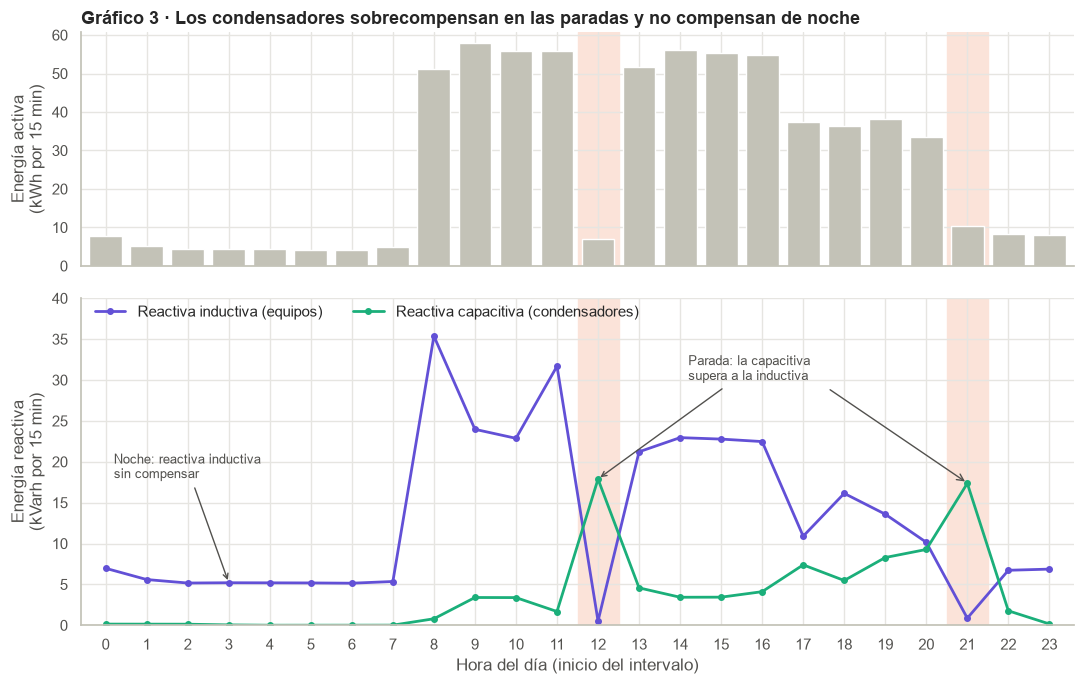

In [9]:
# =============================================================
# Celda 8: GRÁFICO 3 - Reactiva inductiva vs. capacitiva por hora
# =============================================================
# Promedio por hora de la energía activa y de los dos tipos de reactiva
por_hora = df.groupby("hora")[["consumo_kwh",
                               "reactiva_inductiva_kvarh",
                               "reactiva_capacitiva_kvarh"]].mean()

# Dos paneles que comparten el eje X (sharex=True).
# height_ratios da más altura al panel de reactiva, que es el protagonista.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1.4]})

# --- Panel superior: contexto de producción (gris, para no competir) ---
ax1.bar(por_hora.index, por_hora["consumo_kwh"], color="#c3c2b7", width=0.8)
ax1.set_ylabel("Energía activa\n(kWh por 15 min)")
ax1.set_title("Gráfico 3 · Los condensadores sobrecompensan en las paradas y no compensan de noche")

# --- Panel inferior: los dos tipos de reactiva ---
ax2.plot(por_hora.index, por_hora["reactiva_inductiva_kvarh"], color=COLOR_INDUCTIVA,
         linewidth=2, marker="o", markersize=4, label="Reactiva inductiva (equipos)")
ax2.plot(por_hora.index, por_hora["reactiva_capacitiva_kvarh"], color=COLOR_CAPACITIVA,
         linewidth=2, marker="o", markersize=4, label="Reactiva capacitiva (condensadores)")

# Resaltamos las dos horas de parada (12:00 y 21:00) en AMBOS paneles,
# para que el ojo conecte "baja la producción" con "sube la capacitiva".
for hora_parada in [12, 21]:
    for ax in (ax1, ax2):
        ax.axvspan(hora_parada - 0.5, hora_parada + 0.5, color="#fbe3d9", zorder=0)

# Anotaciones con el hallazgo (una sola caja de texto con dos flechas)
ax2.annotate("Parada: la capacitiva\nsupera a la inductiva", xy=(12, 17.9), xytext=(14.2, 30),
             fontsize=9, color=COLOR_TEXTO, arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))
ax2.annotate("", xy=(21, 17.4), xytext=(17.6, 29),
             arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))
ax2.annotate("Noche: reactiva inductiva\nsin compensar", xy=(3, 5.2), xytext=(0.2, 18),
             fontsize=9, color=COLOR_TEXTO, arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))

ax2.set_ylabel("Energía reactiva\n(kVarh por 15 min)")
ax2.set_xlabel("Hora del día (inicio del intervalo)")
ax2.set_xticks(range(24))
ax2.set_xlim(-0.6, 23.6)
ax2.set_ylim(0, 40)
ax2.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 1.02), ncol=2)

sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "g3_reactiva_por_hora.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# =============================================================
# Celda 9: ¿Dónde se concentra el costo de penalización?
# =============================================================
# 1) Por tipo de carga: % de la energía vs. % del costo de penalización
pen = df.groupby("tipo_carga", observed=True).agg(
    consumo_kwh=("consumo_kwh", "sum"),
    costo_penalizacion_usd=("costo_penalizacion_usd", "sum"),
)
pen["% de la energía"] = pen["consumo_kwh"] / pen["consumo_kwh"].sum() * 100
pen["% de la penalización"] = pen["costo_penalizacion_usd"] / pen["costo_penalizacion_usd"].sum() * 100
print(pen.round(1))

# 2) Horas de sobrecompensación: % de intervalos en que la capacitiva
#    supera a la inductiva (los condensadores inyectan más de lo necesario)
sobrecompensa = df["reactiva_capacitiva_kvarh"] > df["reactiva_inductiva_kvarh"]
print("\n% de intervalos con sobrecompensación:")
print((sobrecompensa.groupby(df["hora"]).mean() * 100).round(0).loc[[3, 10, 12, 15, 21]])

# 3) Peso de la madrugada (00:00-07:59) en el costo de penalización
madrugada = df["hora"].between(0, 7)
print(f"\nLa madrugada genera el "
      f"{df.loc[madrugada, 'costo_penalizacion_usd'].sum() / df['costo_penalizacion_usd'].sum() * 100:.0f} %"
      f" del costo de penalización")

              consumo_kwh  costo_penalizacion_usd  % de la energía  \
tipo_carga                                                           
Light_Load       155896.4                  5609.5             16.2   
Medium_Load      372766.5                   878.1             38.8   
Maximum_Load     430977.4                  1604.7             44.9   

              % de la penalización  
tipo_carga                          
Light_Load                    69.3  
Medium_Load                   10.9  
Maximum_Load                  19.8  

% de intervalos con sobrecompensación:
hora
3      1.0
10    23.0
12    98.0
15    24.0
21    93.0
dtype: float64

La madrugada genera el 44 % del costo de penalización


In [11]:
# =============================================================
# Celda 10: Carga de KPIs diarios y detección de días atípicos
# =============================================================
kpi = pd.read_csv(BASE_DIR / "data" / "processed" / "kpi_diario.csv",
                  parse_dates=["fecha"])

# CO2 en toneladas (más legible que kg a escala diaria)
kpi["co2_t"] = kpi["co2_estimado_kg"] / 1000

# Días de la semana en español y en orden lunes → domingo
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dias_es = {"Monday": "Lun", "Tuesday": "Mar", "Wednesday": "Mié", "Thursday": "Jue",
           "Friday": "Vie", "Saturday": "Sáb", "Sunday": "Dom"}
kpi["dia_es"] = pd.Categorical(kpi["dia_semana"].map(dias_es),
                               categories=[dias_es[d] for d in orden_dias], ordered=True)

# Días laborales ATÍPICOS: aplicamos el mismo criterio IQR del ETL, pero
# solo sobre días laborales y buscando valores anormalmente BAJOS.
# Un lunes que emite como un domingo merece explicación.
laborales = kpi[kpi["tipo_dia"] == "Weekday"]
q1, q3 = laborales["co2_t"].quantile([0.25, 0.75])
limite_bajo = q1 - 1.5 * (q3 - q1)
kpi["atipico_bajo"] = (kpi["tipo_dia"] == "Weekday") & (kpi["co2_t"] < limite_bajo)

print(f"Límite inferior: {limite_bajo:.2f} t/día")
print(kpi.loc[kpi["atipico_bajo"], ["fecha", "dia_semana", "co2_t"]].round(3))

Límite inferior: 0.26 t/día
         fecha dia_semana  co2_t
0   2018-01-01     Monday  0.148
45  2018-02-15   Thursday  0.141
46  2018-02-16     Friday  0.140
120 2018-05-01    Tuesday  0.126
212 2018-08-01  Wednesday  0.113
213 2018-08-02   Thursday  0.116
214 2018-08-03     Friday  0.120
266 2018-09-24     Monday  0.114
267 2018-09-25    Tuesday  0.111
268 2018-09-26  Wednesday  0.109
358 2018-12-25    Tuesday  0.147
364 2018-12-31     Monday  0.143


C:\Users\maria\AppData\Local\Temp\ipykernel_30976\2253669767.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(kpi.loc[kpi["atipico_bajo"], ["fecha", "dia_semana", "co2_t"]].round(3))


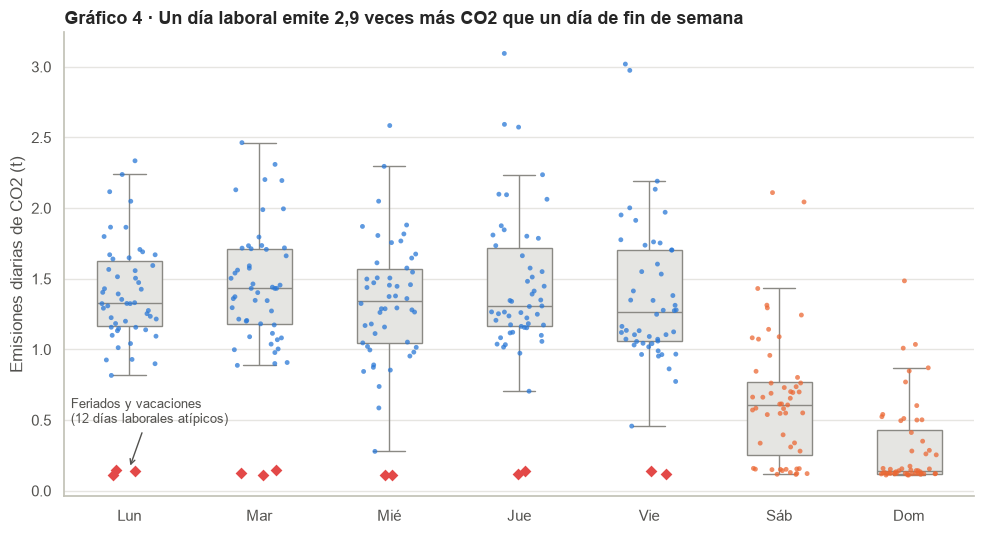

In [12]:
# =============================================================
# Celda 11: GRÁFICO 4 - Emisiones diarias de CO2 por día de la semana
# =============================================================
normales = kpi[~kpi["atipico_bajo"]]

fig, ax = plt.subplots(figsize=(10, 5.5))

# 1) Cajas en gris neutro: resumen estadístico de los días normales.
#    La caja va del percentil 25 al 75; la línea interior es la mediana.
#    showfliers=False porque los puntos individuales ya se dibujan encima.
sns.boxplot(data=normales, x="dia_es", y="co2_t", color="#e6e5e1", width=0.5,
            showfliers=False, linecolor="#8a8984", ax=ax)

# 2) Cada día real como un punto. "jitter" los dispersa horizontalmente
#    para que no se tapen entre sí. Mismos colores de los gráficos anteriores.
sns.stripplot(data=normales, x="dia_es", y="co2_t", hue="tipo_dia",
              palette={"Weekday": COLOR_LABORAL, "Weekend": COLOR_FINDE},
              size=3.5, alpha=0.75, jitter=0.22, legend=False, ax=ax)

# 3) Los días atípicos, destacados con rombos rojos
sns.stripplot(data=kpi[kpi["atipico_bajo"]], x="dia_es", y="co2_t",
              color="#e34948", size=6, marker="D", jitter=0.15, ax=ax)

ax.annotate("Feriados y vacaciones\n(12 días laborales atípicos)",
            xy=(0, 0.16), xytext=(-0.45, 0.48), fontsize=9, color=COLOR_TEXTO,
            arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))

ax.set_xlabel("")
ax.set_ylabel("Emisiones diarias de CO2 (t)")
ax.set_title("Gráfico 4 · Un día laboral emite 2,9 veces más CO2 que un día de fin de semana")
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "g4_co2_dia_semana.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# =============================================================
# Celda 12: Cifras clave de emisiones
# =============================================================
prom = kpi.groupby("tipo_dia")["co2_t"].mean()
print(f"CO2 promedio día laboral      : {prom['Weekday']:.2f} t")
print(f"CO2 promedio fin de semana    : {prom['Weekend']:.2f} t")
print(f"Relación laboral / fin semana : {prom['Weekday'] / prom['Weekend']:.1f} veces")

# "Piso" de emisiones: lo que la planta emite en un día SIN producción
piso = kpi["co2_t"].min()
print(f"\nPiso diario (día sin producción): {piso:.2f} t")
print(f"Piso anual (piso × 365 días)    : {piso * 365:.0f} t "
      f"= {piso * 365 / kpi['co2_t'].sum() * 100:.0f} % del total anual")

CO2 promedio día laboral      : 1.36 t
CO2 promedio fin de semana    : 0.47 t
Relación laboral / fin semana : 2.9 veces

Piso diario (día sin producción): 0.11 t
Piso anual (piso × 365 días)    : 40 t = 10 % del total anual


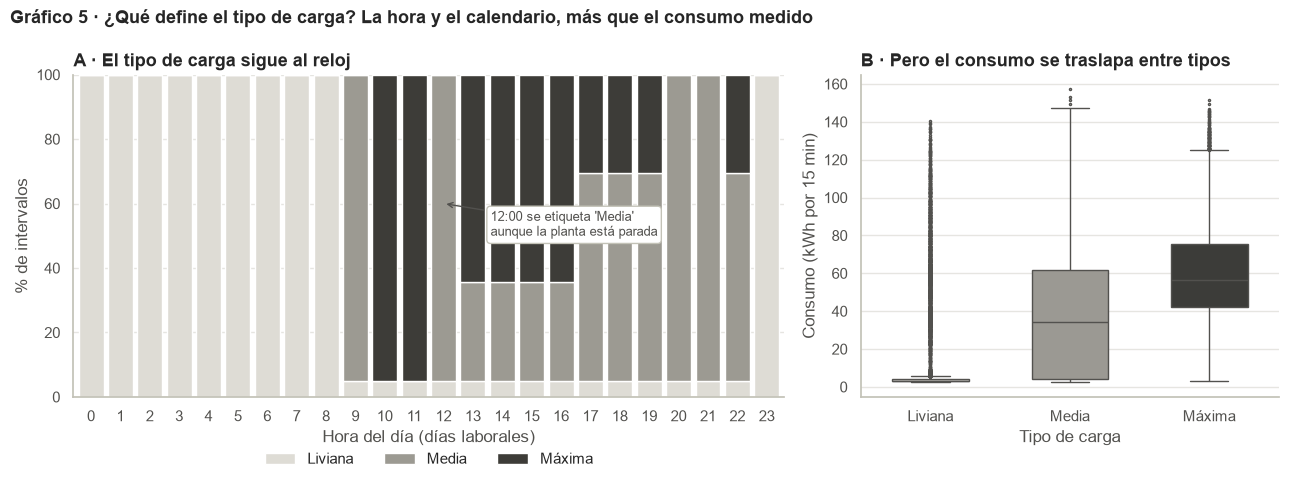

In [15]:
# =============================================================
# Celda 13: GRÁFICO 5 - ¿Qué define el tipo de carga?
# =============================================================
# Colores: tipo_carga tiene ORDEN (liviana < media < máxima), así que usamos
# una escala secuencial de un solo tono, de claro a oscuro.
# Más oscuro = más carga. Un arcoíris confundiría ese orden.
COLORES_CARGA = {"Light_Load": "#dedcd5", "Medium_Load": "#9c9a92", "Maximum_Load": "#3d3c38"}
NOMBRES_CARGA = {"Light_Load": "Liviana", "Medium_Load": "Media", "Maximum_Load": "Máxima"}
TIPOS = ["Light_Load", "Medium_Load", "Maximum_Load"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5),
                               gridspec_kw={"width_ratios": [1.7, 1]})

# --- Panel A: composición del tipo de carga por hora (solo días laborales) ---
# crosstab cuenta combinaciones hora × tipo; normalize="index" lo pasa a
# proporción dentro de cada hora (cada barra suma 100 %).
laborales = df[df["tipo_dia"] == "Weekday"]
mezcla = pd.crosstab(laborales["hora"], laborales["tipo_carga"], normalize="index") * 100

base = np.zeros(24)   # altura acumulada para apilar las barras
for tipo in TIPOS:
    ax1.bar(mezcla.index, mezcla[tipo], bottom=base, color=COLORES_CARGA[tipo],
            width=0.85, edgecolor="white", linewidth=1, label=NOMBRES_CARGA[tipo])
    base += mezcla[tipo].values

ax1.set_xticks(range(24))
ax1.set_xlim(-0.6, 23.6)
ax1.set_ylim(0, 100)
ax1.set_xlabel("Hora del día (días laborales)")
ax1.set_ylabel("% de intervalos")
ax1.set_title("A · El tipo de carga sigue al reloj")
ax1.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.13))
ax1.annotate("12:00 se etiqueta 'Media'\naunque la planta está parada",
             xy=(12, 60), xytext=(13.6, 50), fontsize=9, color=COLOR_TEXTO,
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#c3c2b7"),
             arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))

# --- Panel B: distribución del consumo por tipo de carga ---
sns.boxplot(data=df, x="tipo_carga", y="consumo_kwh", hue="tipo_carga",
            palette=COLORES_CARGA, legend=False, dodge=False, width=0.55,
            fliersize=1.5, linecolor=COLOR_TEXTO, ax=ax2)
ax2.set_xticks([0, 1, 2])
ax2.set_xticklabels([NOMBRES_CARGA[t] for t in TIPOS])
ax2.set_xlabel("Tipo de carga")
ax2.set_ylabel("Consumo (kWh por 15 min)")
ax2.set_title("B · Pero el consumo se traslapa entre tipos")

fig.suptitle("Gráfico 5 · ¿Qué define el tipo de carga? La hora y el calendario, más que el consumo medido",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "g5_tipo_carga.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# =============================================================
# Celda 14: Perfil por tipo de carga + ¿cuánto explica el reloj?
# =============================================================
# 1) Mediana de las variables eléctricas por tipo de carga.
#    Usamos MEDIANA porque las distribuciones son muy asimétricas.
perfil_carga = df.groupby("tipo_carga", observed=True)[
    ["consumo_kwh", "fp_atraso_pct", "ratio_reactiva_activa"]].median()
perfil_carga["% intervalos penalizados"] = (
    df.groupby("tipo_carga", observed=True)["penalizado"].mean() * 100)
print(perfil_carga.round(2))

# 2) "Regla del reloj": para cada combinación de variables de calendario,
#    predecimos el tipo de carga MÁS FRECUENTE (la moda) y medimos el % de aciertos.
#    No es un modelo de machine learning: es una tabla de consulta.
#    Si acierta mucho, el tipo de carga depende del calendario.
for variables in [["hora"], ["hora", "mes"], ["hora", "mes", "dia_semana"]]:
    moda = (df.groupby(variables, observed=True)["tipo_carga"]
              .agg(lambda s: s.mode()[0]).rename("prediccion"))
    resultado = df.join(moda, on=variables)
    acierto = (resultado["prediccion"] == resultado["tipo_carga"]).mean() * 100
    print(f"Regla con {variables}: {acierto:.1f} % de aciertos")

              consumo_kwh  fp_atraso_pct  ratio_reactiva_activa  \
tipo_carga                                                        
Light_Load           3.31          66.27                   1.13   
Medium_Load         34.44          96.82                   0.26   
Maximum_Load        56.63          91.71                   0.43   

              % intervalos penalizados  
tipo_carga                              
Light_Load                       79.05  
Medium_Load                      19.56  
Maximum_Load                     34.47  
Regla con ['hora']: 81.4 % de aciertos
Regla con ['hora', 'mes']: 90.1 % de aciertos
Regla con ['hora', 'mes', 'dia_semana']: 93.3 % de aciertos
